In [ ]:
from huggingface_hub import hf_hub_download
import numpy as np

path = hf_hub_download("TYessine/airwise-rf-coverage-maps", "val.npz", repo_type="dataset")
d = np.load(path)

print("tables:", list(d.keys()))
print("towns:", len(d["scene_names"]), "| maps:", len(d["altitude"]), "| scene_idx max:", d["scene_idx"].max())
print("towns per person:", dict(zip(*np.unique(d["scene_source"], return_counts=True))))
mine = d["scene_names"][d["scene_source"] == "mahdi"]
print("my towns:", mine[0], "...", mine[-1], "(", len(mine), ")")
names = d["scene_names"][d["scene_idx"]]
src = d["scene_source"][d["scene_idx"]]
print("maps per person:", dict(zip(*np.unique(src, return_counts=True))))
print("altitudes:", np.unique(d["altitude"]))
print("dB range:", d["target_db"].min(), "to", d["target_db"].max())

tables: ['heights', 'scene_names', 'scene_hash', 'scene_idx', 'station_pos', 'altitude', 'target_db', 'rt_time', 'scene_source']
towns: 135 | maps: 1620 | scene_idx max: 134
towns per person: {np.str_('mahdi'): np.int64(45), np.str_('sami'): np.int64(45), np.str_('yessine'): np.int64(45)}
my towns: blocks_0270 ... downtown_0284 ( 45 )
maps per person: {np.str_('mahdi'): np.int64(540), np.str_('sami'): np.int64(540), np.str_('yessine'): np.int64(540)}
altitudes: [15. 30. 45. 60.]
dB range: -150.0 to -54.018295


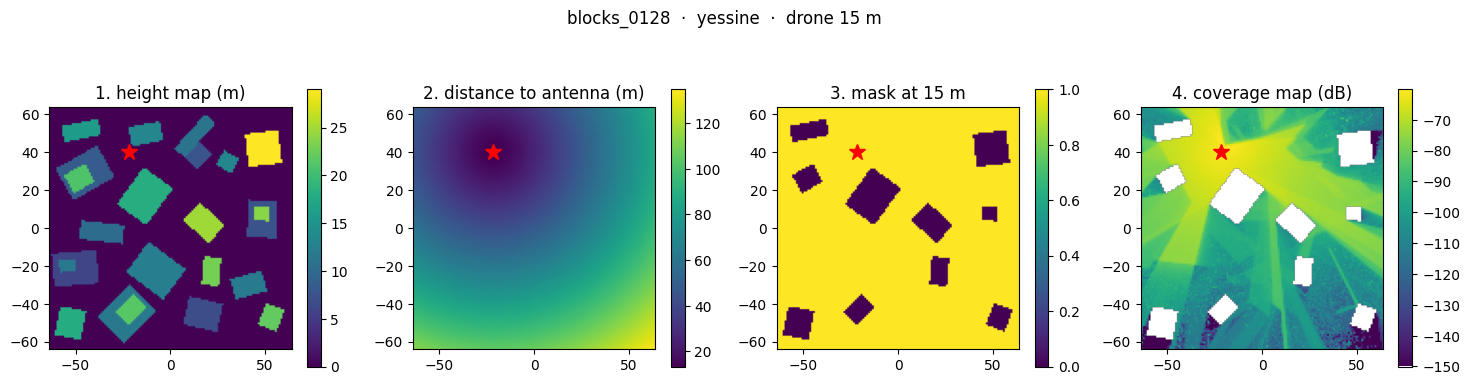

In [ ]:
import matplotlib.pyplot as plt

k = 100                                        # which map to look at (try other numbers)
t = d["scene_idx"][k]
H = d["heights"][t]                            # 1. height map
alt = d["altitude"][k]
sx, sy, sz = d["station_pos"][k]

# 2. station image: 3D distance from the antenna to each square, at the drone's height
ii, jj = np.mgrid[0:128, 0:128]                # row i, column j
x, y = jj - 63.5, ii - 63.5                    # position of each square in metres
dist = np.sqrt((x - sx)**2 + (y - sy)**2 + (alt - sz)**2)

mask = H < alt - 0.5                           # 3. where a drone can be
target = np.where(mask, d["target_db"][k], np.nan)   # 4. Sionna's map, inside buildings hidden

fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
for a, img, title in zip(ax, [H, dist, mask, target],
                         ["1. height map (m)", "2. distance to antenna (m)", f"3. mask at {alt:.0f} m", "4. coverage map (dB)"]):
    im = a.imshow(img, origin="lower", extent=[-64, 64, -64, 64])
    a.plot(sx, sy, "r*", markersize=12)        # the antenna
    a.set_title(title); fig.colorbar(im, ax=a, shrink=0.8)
fig.suptitle(f"{d['scene_names'][t]}  ·  {d['scene_source'][t]}  ·  drone {alt:.0f} m")
plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class CoverageDataset(Dataset):
    def __init__(self, path):
        d = np.load(path)
        self.heights = d["heights"]          # one height map per town
        self.idx     = d["scene_idx"]        # which town each map belongs to
        self.pos     = d["station_pos"]      # antenna of each map
        self.alt     = d["altitude"]         # drone height of each map
        self.target  = d["target_db"]        # Sionna's maps (the answers)
        ii, jj = np.mgrid[0:128, 0:128]
        self.x = (jj - 63.5).astype(np.float32)   # x of each square, in metres
        self.y = (ii - 63.5).astype(np.float32)   # y of each square, in metres

    def __len__(self):                       # how many examples
        return len(self.alt)

    def __getitem__(self, k):                # build example number k
        H = self.heights[self.idx[k]]
        sx, sy, sz = self.pos[k]
        alt = self.alt[k]
        dist = np.sqrt((self.x - sx)**2 + (self.y - sy)**2 + (alt - sz)**2)
        inputs = np.stack([H / 60,                                  # 1. height map
                           dist / 200,                              # 2. distance to antenna
                           np.full((128, 128), alt / 60)])          # 3. drone height
        answer = (self.target[k] + 150) / 100                       # Sionna's map, scaled
        mask = H < alt - 0.5                                        # squares that count
        return (torch.tensor(inputs, dtype=torch.float32),
                torch.tensor(answer[None], dtype=torch.float32),
                torch.tensor(mask[None], dtype=torch.float32))

val_ds = CoverageDataset(path)
inputs, answer, mask = val_ds[100]
print("examples:", len(val_ds))
print("inputs:", inputs.shape, "| answer:", answer.shape, "| mask:", mask.shape)

loader = DataLoader(val_ds, batch_size=16, shuffle=True)
xb, yb, mb = next(iter(loader))
print("one batch:", xb.shape, yb.shape, mb.shape)

examples: 1620
inputs: torch.Size([3, 128, 128]) | answer: torch.Size([1, 128, 128]) | mask: torch.Size([1, 128, 128])
one batch: torch.Size([16, 3, 128, 128]) torch.Size([16, 1, 128, 128]) torch.Size([16, 1, 128, 128])


In [ ]:
import torch.nn as nn

def block(cin, cout):              # one "worker": 2 layers that look at 3×3 windows
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.down1  = block(3, 32)        # left side, 128×128
        self.down2  = block(32, 64)       # left side, 64×64
        self.down3  = block(64, 128)      # left side, 32×32
        self.bottom = block(128, 256)     # bottom, 16×16 (sees the whole town)
        self.shrink = nn.MaxPool2d(2)     # zoom out: 2×2 squares → 1 (keeps the biggest)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2); self.mix3 = block(256, 128)   # right side, 32×32
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2);  self.mix2 = block(128, 64)    # right side, 64×64
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2);   self.mix1 = block(64, 32)     # right side, 128×128
        self.out = nn.Conv2d(32, 1, 1)    # last layer: one number per square

    def forward(self, x):                 # the trip through the U (the guess)
        a = self.down1(x)                         # 128×128 → kept for the shortcut
        b = self.down2(self.shrink(a))            # 64×64   → kept
        c = self.down3(self.shrink(b))            # 32×32   → kept
        z = self.bottom(self.shrink(c))           # 16×16
        z = self.mix3(torch.cat([self.up3(z), c], 1))   # enlarge to 32, glue c (shortcut), mix
        z = self.mix2(torch.cat([self.up2(z), b], 1))   # enlarge to 64, glue b, mix
        z = self.mix1(torch.cat([self.up1(z), a], 1))   # enlarge to 128, glue a, mix
        return self.out(z)

model = UNet()
print("knobs:", sum(p.numel() for p in model.parameters()))

pred = model(xb)                                         # guess the 16 maps of the batch
print("prediction:", pred.shape)

loss = (((pred - yb) ** 2) * mb).sum() / mb.sum()          # masked MSE
print("RMSE: %.1f dB" % (loss.item() ** 0.5 * 100))        # square root, back to dB

knobs: 1928417
prediction: torch.Size([16, 1, 128, 128])
RMSE: 88.2 dB


In [ ]:
# ---- 1. where to compute, and where to save ----
from google.colab import drive
drive.mount('/content/drive')                     # to save the trained network in your Drive
device = "cuda" if torch.cuda.is_available() else "cpu"
print("using:", device)                           # should say: cuda (= the GPU)

# ---- 2. the data: train to learn, val to check ----
train_path = hf_hub_download("TYessine/airwise-rf-coverage-maps", "train.npz", repo_type="dataset")
train_ds = CoverageDataset(train_path)            # 12,960 maps
val_ds   = CoverageDataset(path)                  # 1,620 maps (val.npz, from the first cell)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,  num_workers=2)   # the waiter: trays of 16, shuffled
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)

# ---- 3. a fresh U-Net, and the tool that turns the knobs ----
model = UNet().to(device)                          # random knobs, on the GPU
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)   # turns the knobs; lr = size of each nudge

def masked_mse(pred, answer, mask):                # our loss: MSE on the cells where the drone can be
    return (((pred - answer) ** 2) * mask).sum() / mask.sum()

# ---- 4. training ----
best = float("inf")
for epoch in range(1, 21):                         # 20 epochs = 20 times through all the training maps
    model.train(); total = 0
    for x, y, m in train_loader:                   # one tray (batch) at a time
        x, y, m = x.to(device), y.to(device), m.to(device)
        loss = masked_mse(model(x), y, m)          # guess + error
        optimizer.zero_grad()                      # forget the previous gradients
        loss.backward()                            # gradient: which way to turn each knob (going back through the U)
        optimizer.step()                           # turn every knob a little
        total += loss.item()
    train_rmse = (total / len(train_loader)) ** 0.5 * 100

    model.eval(); se = 0; n = 0                    # check on val: no knob changes here
    with torch.no_grad():
        for x, y, m in val_loader:
            x, y, m = x.to(device), y.to(device), m.to(device)
            se += (((model(x) - y) ** 2) * m).sum().item()
            n  += m.sum().item()
    val_rmse = (se / n) ** 0.5 * 100

    print(f"epoch {epoch:2d}: train RMSE {train_rmse:.1f} dB | val RMSE {val_rmse:.1f} dB")
    if val_rmse < best:                            # keep the version with the best val error
        best = val_rmse
        torch.save(model.state_dict(), "/content/drive/MyDrive/AIRWISE/best_unet.pt")
        print("   saved: best so far")

Mounted at /content/drive
using: cuda


train.npz: reconstructing file:   0%|          |  0.00B /  660MB            

train.npz: downloading bytes:           |  0.00B            

epoch  1: train RMSE 15.4 dB | val RMSE 12.6 dB
   saved: best so far
epoch  2: train RMSE 12.9 dB | val RMSE 12.6 dB
   saved: best so far
epoch  3: train RMSE 12.3 dB | val RMSE 11.8 dB
   saved: best so far
epoch  4: train RMSE 12.0 dB | val RMSE 11.8 dB
epoch  5: train RMSE 11.6 dB | val RMSE 10.9 dB
   saved: best so far
epoch  6: train RMSE 11.3 dB | val RMSE 10.7 dB
   saved: best so far
epoch  7: train RMSE 11.1 dB | val RMSE 10.4 dB
   saved: best so far
epoch  8: train RMSE 10.9 dB | val RMSE 10.6 dB
epoch  9: train RMSE 10.7 dB | val RMSE 10.3 dB
   saved: best so far
epoch 10: train RMSE 10.6 dB | val RMSE 10.3 dB
epoch 11: train RMSE 10.4 dB | val RMSE 10.3 dB
epoch 12: train RMSE 10.3 dB | val RMSE 10.2 dB
   saved: best so far
epoch 13: train RMSE 10.1 dB | val RMSE 10.1 dB
   saved: best so far
epoch 14: train RMSE 9.9 dB | val RMSE 10.1 dB
   saved: best so far
epoch 15: train RMSE 9.7 dB | val RMSE 10.0 dB
   saved: best so far
epoch 16: train RMSE 9.4 dB | val RMSE 1

test.npz: reconstructing file:   0%|          |  0.00B / 82.4MB            

test.npz: downloading bytes:           |  0.00B            

test: RMSE 10.4 dB | MAE 6.9 dB


ood.npz: reconstructing file:   0%|          |  0.00B /  165MB            

ood.npz: downloading bytes:           |  0.00B            

ood: RMSE 12.3 dB | MAE 7.8 dB
speed: 1.41 ms per map  (Sionna: about 300 ms)


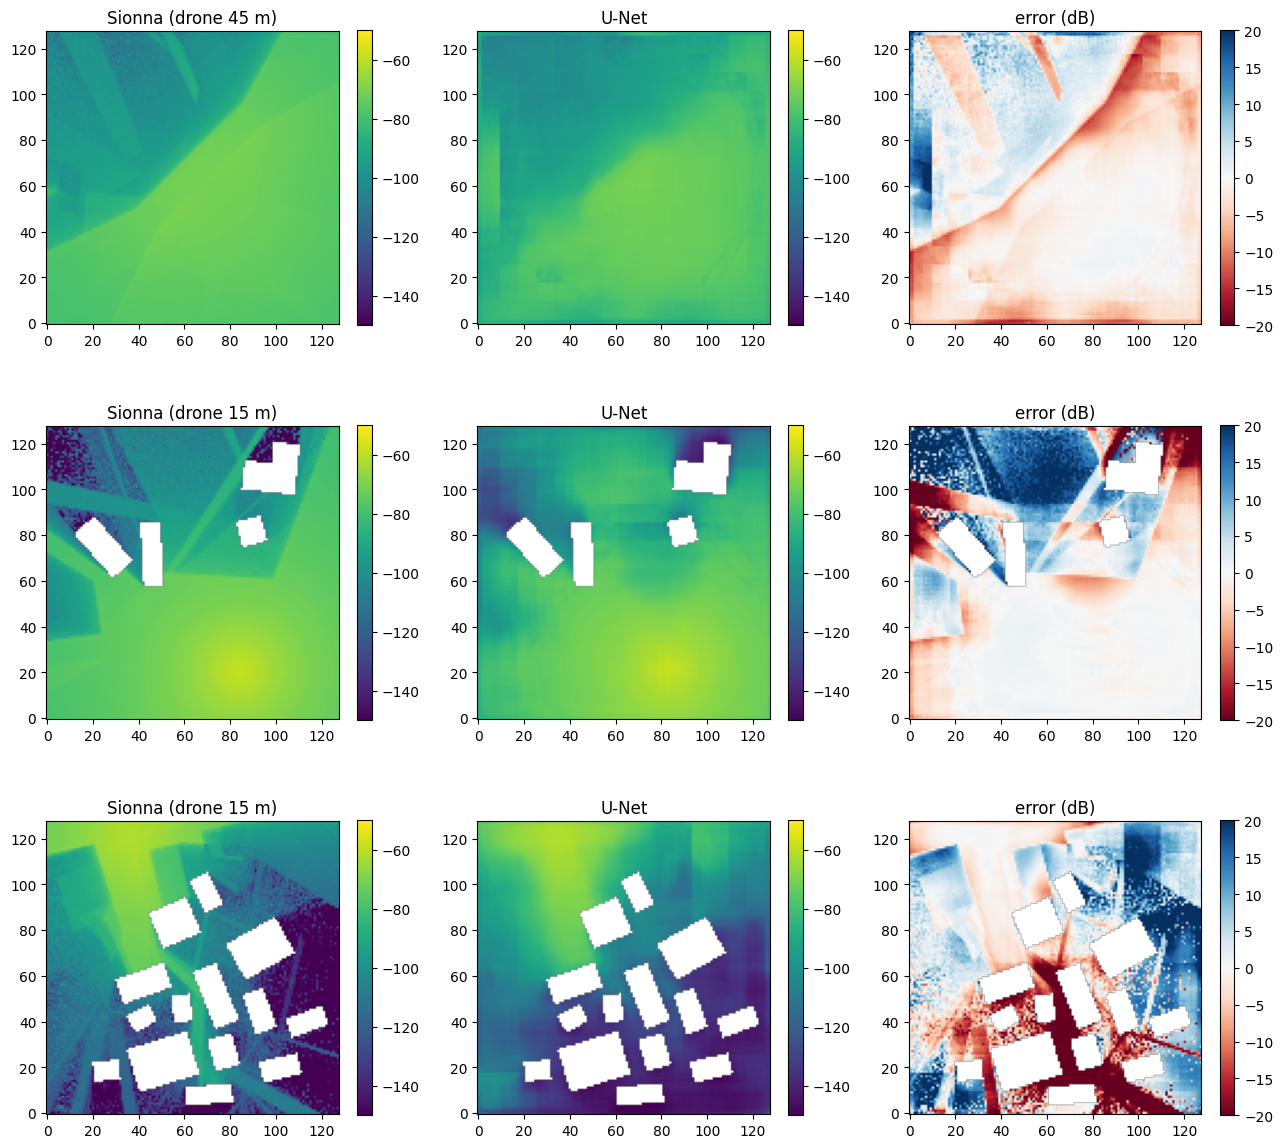

In [ ]:
import time, matplotlib.pyplot as plt

# ---- load the best trained network (epoch 15) ----
model = UNet().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/AIRWISE/best_unet.pt", map_location=device))
model.eval()

# ---- final grades: RMSE and MAE in dB, only on cells where the drone can be ----
def evaluate(name):
    p = hf_hub_download("TYessine/airwise-rf-coverage-maps", f"{name}.npz", repo_type="dataset")
    ds = CoverageDataset(p)
    loader = DataLoader(ds, batch_size=32, shuffle=False, num_workers=2)
    se = ae = n = 0
    with torch.no_grad():
        for x, y, m in loader:
            x, y, m = x.to(device), y.to(device), m.to(device)
            diff = (model(x) - y) * 100                    # error of each cell, in dB
            se += ((diff ** 2) * m).sum().item()
            ae += (diff.abs() * m).sum().item()
            n  += m.sum().item()
    print(f"{name}: RMSE {(se / n) ** 0.5:.1f} dB | MAE {ae / n:.1f} dB")
    return ds

test_ds = evaluate("test")
ood_ds  = evaluate("ood")

# ---- speed: time to predict one map ----
x, _, _ = next(iter(DataLoader(test_ds, batch_size=32)))
x = x.to(device)
with torch.no_grad():
    model(x); torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(10):
        model(x)
    torch.cuda.synchronize()
print(f"speed: {(time.time() - t0) / (10 * 32) * 1000:.2f} ms per map  (Sionna: about 300 ms)")

# ---- pictures: Sionna vs U-Net vs error, for 3 test maps ----
fig, ax = plt.subplots(3, 3, figsize=(13, 12))
for r, k in enumerate([10, 700, 1500]):
    x, y, m = test_ds[k]
    with torch.no_grad():
        pred = model(x[None].to(device))[0, 0].cpu().numpy()
    valid = m[0].numpy() > 0
    true_db = np.where(valid, y[0].numpy() * 100 - 150, np.nan)
    pred_db = np.where(valid, pred * 100 - 150, np.nan)
    alt = test_ds.alt[k]
    for c, (img, title, cmap, lo, hi) in enumerate([
            (true_db, f"Sionna (drone {alt:.0f} m)", "viridis", -150, -50),
            (pred_db, "U-Net", "viridis", -150, -50),
            (pred_db - true_db, "error (dB)", "RdBu", -20, 20)]):
        im = ax[r, c].imshow(img, origin="lower", cmap=cmap, vmin=lo, vmax=hi)
        ax[r, c].set_title(title); fig.colorbar(im, ax=ax[r, c], shrink=0.8)
plt.tight_layout(); plt.show()